# Expected goals: shot geometry and training

**Analytical question:** Estimate shot-outcome probability.

**Stages in this notebook:** Distance and opening angle; logistic link; gradient-based optimizer; synthetic check.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Inspect shot-to-goal geometry

Build vectors to both posts before using distance and opening angle as features.

,dx_to_post,dy_to_post
0,17.5,-15.66
1,17.5,-8.34


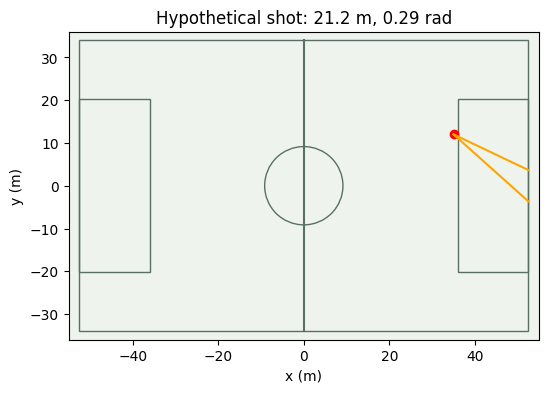

In [4]:
def goal_geometry(point):
    posts=np.array([[52.5,-3.66],[52.5,3.66]])
    vectors=posts-np.asarray(point);distance=np.linalg.norm(np.array([52.5,0])-point)
    cosine=np.dot(vectors[0],vectors[1])/(np.linalg.norm(vectors[0])*np.linalg.norm(vectors[1]))
    return posts,vectors,distance,np.arccos(np.clip(cosine,-1,1))
shot=np.array([35.,12.]);posts,vectors,distance,angle=goal_geometry(shot);display(pd.DataFrame(vectors,columns=['dx_to_post','dy_to_post']))
fig,ax=plt.subplots(figsize=(8,4));pitch(ax);ax.scatter(*shot,c='red')
for post in posts:ax.plot([shot[0],post[0]],[shot[1],post[1]],c='orange')
ax.set_title(f'Hypothetical shot: {distance:.1f} m, {angle:.2f} rad');plt.show()

## 5. Manufacture the feature matrix

Apply the geometry consistently to several hypothetical shots.

In [5]:
def shot_features(x,y):
    dx=52.5-np.asarray(x);y=np.asarray(y)
    distance=np.hypot(dx,y)
    a=np.arctan2(3.66-y,dx);b=np.arctan2(-3.66-y,dx)
    angle=np.abs(np.angle(np.exp(1j*(a-b))))
    return np.c_[distance,angle]
feature_table=pd.DataFrame(shot_features([40,30,45],[0,15,-10]),columns=['distance_m','opening_radians']);display(feature_table)

,distance_m,opening_radians
0,12.500000,0.569677
1,27.041635,0.225530
2,12.500000,0.366905


## 6. Inspect the logistic link and loss gradient

A learned linear score becomes a probability through sigmoid. Inspect the residual that drives a gradient step before training.

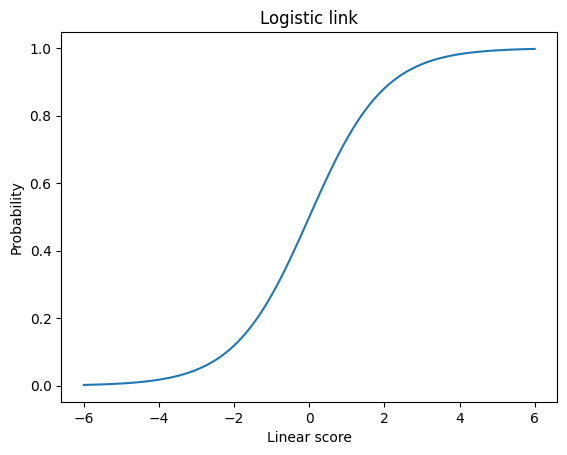

,input,weight,gradient,updated_weight
0,1.0,0.0,-0.50,0.050
1,0.5,0.0,-0.25,0.025
2,-0.2,0.0,0.10,-0.010


In [6]:
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-40,40)))
scores=np.linspace(-6,6,100);plt.plot(scores,sigmoid(scores));plt.xlabel('Linear score');plt.ylabel('Probability');plt.title('Logistic link');plt.show()
toy_row=np.array([1.,.5,-.2]);weights=np.zeros(3);label=1;probability=sigmoid(toy_row@weights);gradient=toy_row*(probability-label)
display(pd.DataFrame({'input':toy_row,'weight':weights,'gradient':gradient,'updated_weight':weights-.1*gradient}))

## 7. Final output: optimizer check on synthetic labels

Use the same sigmoid and residual calculation in the training loop. This verifies optimization, not soccer xG performance.

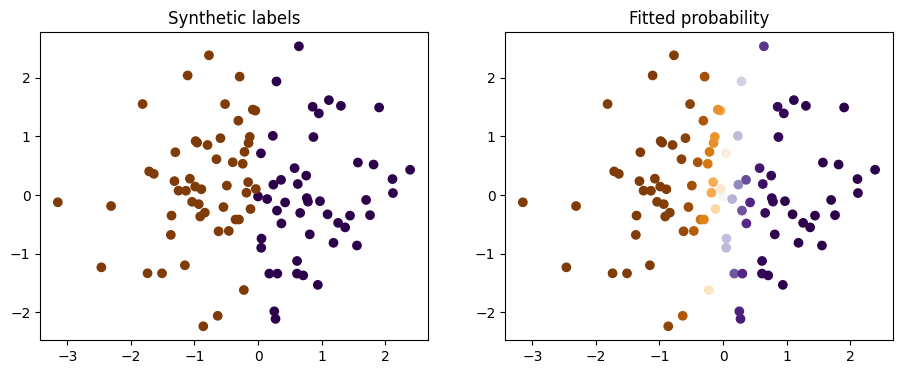

In [7]:
def fit_binary(X,y,steps=1000,lr=.1):
    X=np.c_[np.ones(len(X)),np.asarray(X,float)];w=np.zeros(X.shape[1]);y=np.asarray(y,float)
    for _ in range(steps):w-=lr*X.T@(sigmoid(X@w)-y)/len(y)
    return w
rng=np.random.default_rng(8);toy=rng.normal(size=(100,2));target=(toy[:,0]>0).astype(int);w=fit_binary(toy,target)
probabilities=sigmoid(np.c_[np.ones(len(toy)),toy]@w);assert ((probabilities>.5)==target).mean()>.9
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(toy[:,0],toy[:,1],c=target,cmap='PuOr');axs[0].set_title('Synthetic labels');axs[1].scatter(toy[:,0],toy[:,1],c=probabilities,cmap='PuOr');axs[1].set_title('Fitted probability');plt.show()

## Interpretation and limitations

The shot examples and optimizer labels are explicitly hypothetical/synthetic. Fit, calibrate and test on many real labeled shots before reporting xG. Tracking features such as goalkeeper position and shooting-lane defenders require further engineering.